# Turning Model Scores into Decisions

A model outputs a probability or a score. A business needs an action: review this transaction or let it through. This notebook continues the credit card fraud example from `Anomaly_Detection_Evaluation.ipynb` and covers:

* Choosing a threshold (and why 0.5 is rarely the right one)
* Picking a threshold based on the cost of errors, using real transaction amounts
* Working within operational constraints (limited analyst time)
* Calibration: can you trust the predicted probabilities?
* Communicating results to stakeholders

## Import Libraries

In [1]:
%matplotlib inline

from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibrationDisplay

from sklearn import metrics

## Load the Dataset and Engineer Features

In [2]:
DATA_URL = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'
DATA_PATH = Path('data/creditcard.csv')

# Download the data once (about 150 MB), then read the local copy
if not DATA_PATH.exists():
    urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)

df['hour'] = (df['Time'] // 3600) % 24
df['log_amount'] = np.log1p(df['Amount'])

features = [f'V{i}' for i in range(1, 29)] + ['log_amount', 'hour']

## Train, Validation, and Test Sets

Choosing a threshold is a form of tuning, so it should not be done on the test set. We split the data three ways:

* **Training set (60%):** fit the model
* **Validation set (20%):** choose the threshold
* **Test set (20%):** report final, honest results

In [3]:
train, temp = train_test_split(df, test_size=0.4, stratify=df['Class'], random_state=0)
val, test = train_test_split(temp, test_size=0.5, stratify=temp['Class'], random_state=0)

y_val, y_test = val['Class'].values, test['Class'].values
print(f'Frauds in the validation set: {y_val.sum()}')
print(f'Frauds in the test set:       {y_test.sum()}')

Frauds in the validation set: 98
Frauds in the test set:       99


We use the random forest, the best model from `Anomaly_Detection_Evaluation.ipynb`.

In [4]:
clf = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=0)
clf.fit(train[features], train['Class'])

val_probs = clf.predict_proba(val[features])[:, 1]
test_probs = clf.predict_proba(test[features])[:, 1]

## From Probabilities to Actions

`clf.predict` flags a transaction when its predicted probability is above 0.5. Changing the threshold trades precision for recall: a lower threshold catches more fraud but flags more legitimate transactions.

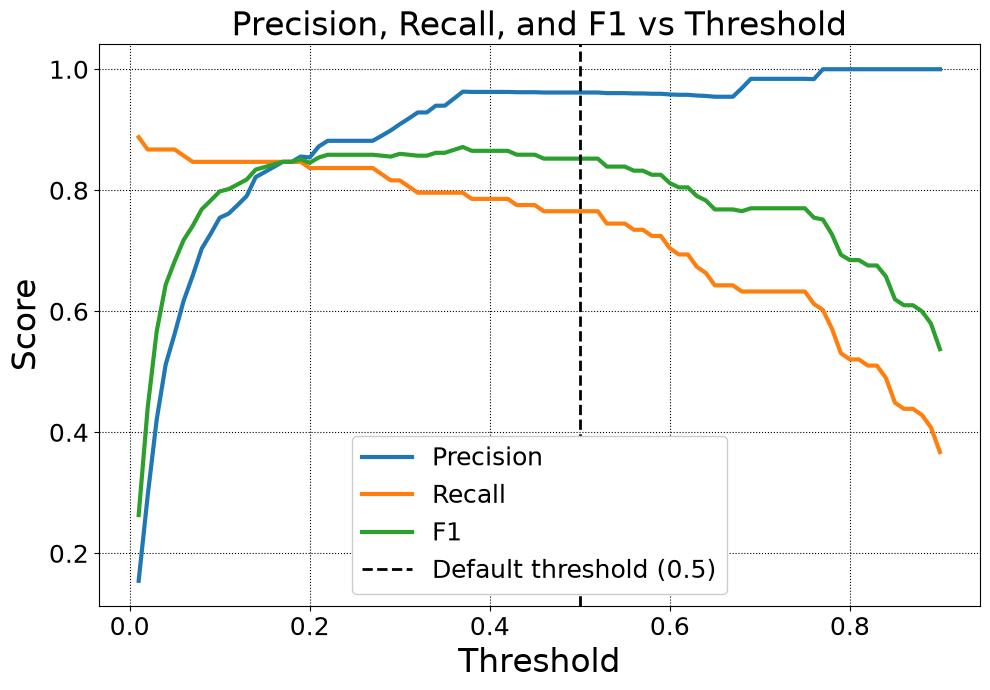

In [5]:
thresholds = np.linspace(0.01, 0.9, 90)

precision = [metrics.precision_score(y_val, val_probs >= t, zero_division=0) for t in thresholds]
recall = [metrics.recall_score(y_val, val_probs >= t) for t in thresholds]
f1 = [metrics.f1_score(y_val, val_probs >= t) for t in thresholds]

fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (10,7), facecolor = 'white')
ax.plot(thresholds, precision, lw=3, label='Precision')
ax.plot(thresholds, recall, lw=3, label='Recall')
ax.plot(thresholds, f1, lw=3, label='F1')
ax.axvline(0.5, color='k', linestyle='--', lw=2, label='Default threshold (0.5)')
ax.grid(True,
        axis = 'both',
        zorder = 0,
        linestyle = ':',
        color = 'k')
ax.tick_params(labelsize = 18)
ax.set_xlabel('Threshold', fontsize = 24)
ax.set_ylabel('Score', fontsize = 24)
ax.set_title('Precision, Recall, and F1 vs Threshold', fontsize = 24)
ax.legend(fontsize = 18, framealpha = 1)
fig.tight_layout()

## Choosing a Threshold Based on Cost

The right threshold depends on what errors cost. This dataset includes the amount of every transaction, so we can use real numbers:

* A **missed fraud** (false negative) costs the **transaction amount**.
* **Reviewing** a flagged transaction (true or false positive) costs **$5** of analyst time.

We pick the threshold that minimizes total cost on the validation set.

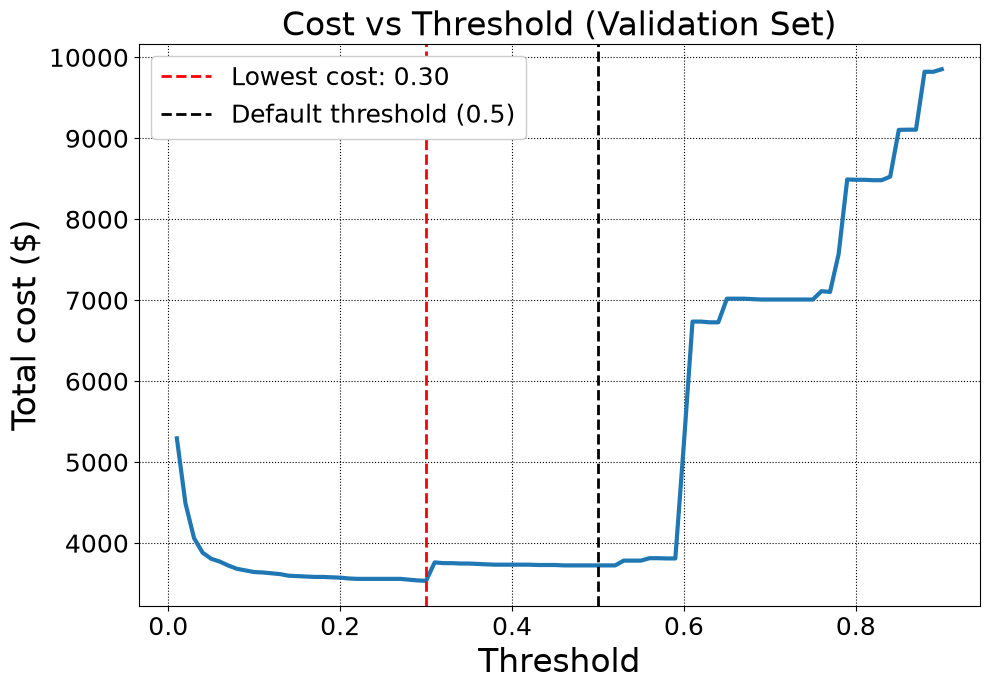

In [6]:
cost_review = 5

def total_cost(data, probs, threshold):
    flagged = probs >= threshold
    missed_fraud = (data['Class'].values == 1) & ~flagged
    return data['Amount'].values[missed_fraud].sum() + flagged.sum() * cost_review

costs = [total_cost(val, val_probs, t) for t in thresholds]
best_threshold = thresholds[np.argmin(costs)]

fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (10,7), facecolor = 'white')
ax.plot(thresholds, costs, lw=3)
ax.axvline(best_threshold, color='r', linestyle='--', lw=2, label=f'Lowest cost: {best_threshold:.2f}')
ax.axvline(0.5, color='k', linestyle='--', lw=2, label='Default threshold (0.5)')
ax.grid(True,
        axis = 'both',
        zorder = 0,
        linestyle = ':',
        color = 'k')
ax.tick_params(labelsize = 18)
ax.set_xlabel('Threshold', fontsize = 24)
ax.set_ylabel('Total cost ($)', fontsize = 24)
ax.set_title('Cost vs Threshold (Validation Set)', fontsize = 24)
ax.legend(fontsize = 18, framealpha = 1)
fig.tight_layout()

The curve is nearly flat between about 0.1 and 0.6: any threshold in that range costs about the same, while very low or very high thresholds are expensive. The big jumps come from individual large frauds being missed.

### Using the Amount in the Decision

A single threshold treats a $2 fraud and a $2,000 fraud the same. Most frauds in this dataset are small (half are under $10), so reviewing them all is not worth it. A rule that sounds smarter uses the amount directly: review a transaction when its **expected loss**, the chance of fraud times the amount, is more than the cost of a review. Does it work?

In [7]:
print(f"Median fraud amount: ${df.loc[df['Class'] == 1, 'Amount'].median():.2f}")

def expected_loss_flags(data, probs):
    return probs * data['Amount'].values > cost_review

def policy_cost(data, flagged):
    missed_fraud = (data['Class'].values == 1) & ~flagged
    return data['Amount'].values[missed_fraud].sum() + flagged.sum() * cost_review

print(f'Validation cost, lowest-cost threshold: ${min(costs):.0f}')
print(f'Validation cost, expected-loss rule:    ${policy_cost(val, expected_loss_flags(val, val_probs)):.0f}')

Median fraud amount: $9.25
Validation cost, lowest-cost threshold: $3535
Validation cost, expected-loss rule:    $4110


## Operational Constraints

Sometimes the constraint is capacity, not cost. If the fraud team can only review **0.2% of transactions** (2 in every 1,000), the threshold is set by that budget: flag the 0.2% of transactions with the highest scores.

In [8]:
review_rate = 0.002
capacity_threshold = np.quantile(val_probs, 1 - review_rate)

print(f'Threshold for a 0.2% review rate: {capacity_threshold:.3f}')
print(f'Recall at that threshold:         {metrics.recall_score(y_val, val_probs >= capacity_threshold):.3f}')
print(f'Precision at that threshold:      {metrics.precision_score(y_val, val_probs >= capacity_threshold):.3f}')

Threshold for a 0.2% review rate: 0.088
Recall at that threshold:         0.847
Precision at that threshold:      0.728


## Calibration

If a model says a transaction has a 20% chance of being fraud, are about 20% of those transactions actually fraud? A model whose probabilities match observed frequencies is **calibrated**. Calibration matters when you use the probabilities directly, as the expected-loss rule above does.

A common trick for rare events is `class_weight='balanced'`, which makes the model pay more attention to the rare class. Let's see what it does to the probabilities of a logistic regression. The dotted diagonal is perfect calibration.

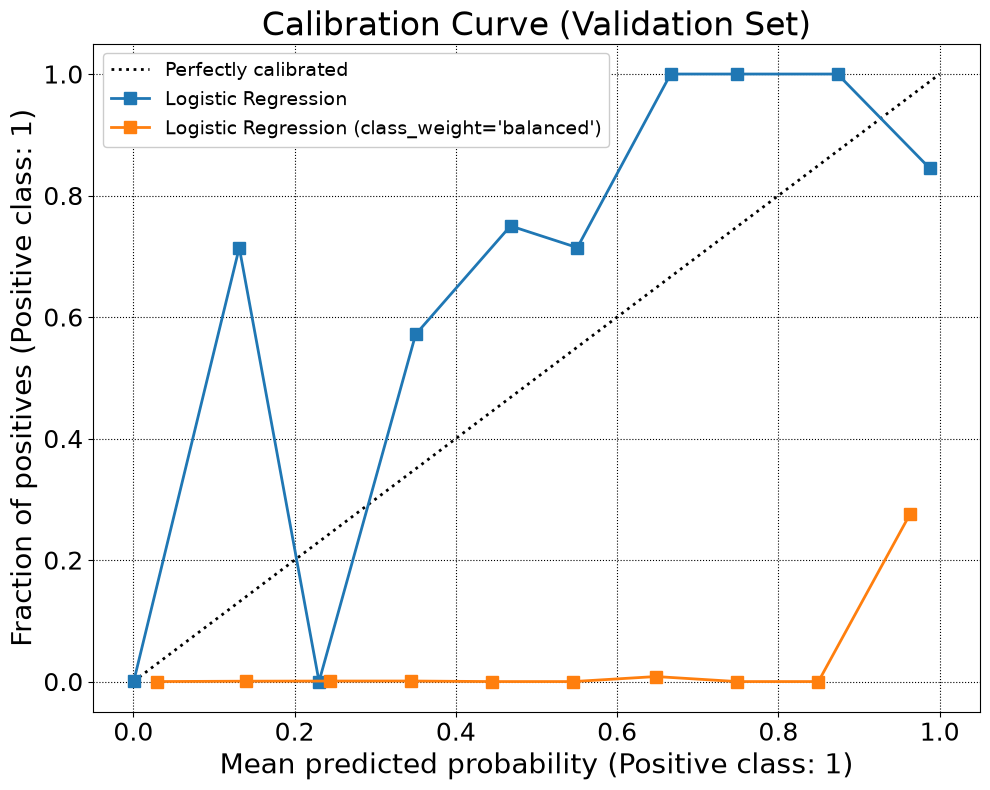

In [9]:
default_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
balanced_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced'))
default_probs = default_lr.fit(train[features], train['Class']).predict_proba(val[features])[:, 1]
balanced_probs = balanced_lr.fit(train[features], train['Class']).predict_proba(val[features])[:, 1]

fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (10,8), facecolor = 'white')
CalibrationDisplay.from_predictions(y_val, default_probs, n_bins=10,
                                    name='Logistic Regression', ax=ax)
CalibrationDisplay.from_predictions(y_val, balanced_probs, n_bins=10,
                                    name="Logistic Regression (class_weight='balanced')", ax=ax)
ax.grid(True,
        axis = 'both',
        zorder = 0,
        linestyle = ':',
        color = 'k')
ax.tick_params(labelsize = 18)
for line in ax.get_lines():
    line.set_linewidth(2)
    line.set_markersize(8)
ax.xaxis.label.set_size(20)
ax.yaxis.label.set_size(20)
ax.legend(loc='upper left', fontsize = 14, framealpha = 1)
ax.set_title('Calibration Curve (Validation Set)', fontsize = 24)
fig.tight_layout()

In [10]:
print(f'Actual fraud rate:               {y_val.mean():.4f}')
print(f'Average prediction (default):    {default_probs.mean():.4f}')
print(f'Average prediction (balanced):   {balanced_probs.mean():.4f}')
print(f'ROC-AUC (default):  {metrics.roc_auc_score(y_val, default_probs):.3f}')
print(f'ROC-AUC (balanced): {metrics.roc_auc_score(y_val, balanced_probs):.3f}')

Actual fraud rate:               0.0017
Average prediction (default):    0.0018
Average prediction (balanced):   0.0781
ROC-AUC (default):  0.973
ROC-AUC (balanced): 0.984


The default curve is jumpy because only a few transactions get scores above 0.1, so each bin holds just a handful of them. The balanced model is wrong across the board: `class_weight='balanced'` ranks transactions about as well as the default model (similar ROC-AUC), but its predicted probabilities are far higher than the actual fraud rate. If you used its scores in the expected-loss rule, you would flag far too many transactions. A model can rank well and still be poorly calibrated. scikit-learn's `CalibratedClassifierCV` can fix this.

## Communicating Results

Stakeholders rarely want to hear "the PR-AUC is 0.85". They want to know what will happen if they use the model. We evaluate each policy **once** on the test set and express the results per 100,000 transactions.

In [11]:
def summarize(data, flagged, label):
    is_fraud = data['Class'].values == 1
    scale = 100000 / len(data)
    return {'policy': label,
            'transactions reviewed': round(flagged.sum() * scale),
            'fraud caught': round((is_fraud & flagged).sum() * scale),
            'fraud missed': round((is_fraud & ~flagged).sum() * scale),
            'false alarms': round((~is_fraud & flagged).sum() * scale),
            'total cost ($)': round(policy_cost(data, flagged) * scale)}

summary = pd.DataFrame([
    summarize(test, test_probs >= 0.5, 'Default threshold (0.5)'),
    summarize(test, test_probs >= best_threshold, f'Lowest-cost threshold ({best_threshold:.2f})'),
    summarize(test, expected_loss_flags(test, test_probs), 'Expected-loss rule'),
    summarize(test, test_probs >= capacity_threshold, 'Review 0.2% of transactions'),
])
summary.set_index('policy')

,transactions reviewed,fraud caught,fraud missed,false alarms,total cost ($)
policy,,,,,
Default threshold (0.5),137,126,47,11,7198
Lowest-cost threshold (0.30),160,135,39,25,6775
Expected-loss rule,502,70,104,432,8005
Review 0.2% of transactions,195,140,33,54,6376


A table like this makes the tradeoff concrete: "If we review about N transactions per 100,000, we catch X frauds, miss Y, and spend $Z in total."

Two things stand out:

* **The expected-loss rule costs more, not less.** It trusts small probabilities: a 2% score on a large purchase is enough to trigger a review, so it flags many large legitimate transactions. A rule like this only works if the probabilities are accurate, which is what calibration checks.
* **The validation set and test set disagree a little.** With fewer than 100 frauds in each, the threshold that was cheapest on the validation set is not exactly the cheapest on the test set. Expect thresholds to move as you collect more data.

## Monitoring

A threshold that works today may not work next month. Once a model is in use, track:

* **Alert rate:** Is the share of flagged transactions changing?
* **Precision of reviewed alerts:** Are analysts still finding fraud in what the model flags?
* **Score and feature distributions:** Has the data drifted from what the model was trained on?

**Key takeaways**
* A threshold is a business decision, not a modeling default.
* Use real costs when you have them. Here, the transaction amount changes which frauds are worth chasing.
* Choose thresholds on a validation set and report results on a test set.
* Check calibration before treating scores as probabilities.
* Communicate results as counts and costs, not just metrics.